# Week 14 - Music Generation: Char-RNN on ABC Notation & MIDI Generation

**Topics (record sections c-g)**
* c. Data preparation for the Char-RNN
* d. Many-to-many sequence preparation
* e. Model architecture (Embedding -> LSTM -> TimeDistributed Dense)
* f. Music generation
* g. MIDI-based generation of tabla-style music

In [1]:
import os, re, glob
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, TimeDistributed

np.random.seed(0); tf.random.set_seed(0)
os.makedirs("data/music", exist_ok=True)

## c. Char-RNN data preparation
We write a small ABC tune to a file (the record writes to `/content/music.abc` on Colab; we use `data/music/`).

In [2]:
music_data = """X:1
T:Simple Rhythm
M:4/4
L:1/8
K:C
C D E G | G E D C |
C C G G | A A G2 |
"""
with open("data/music/music.abc", "w", encoding="utf-8") as file:
    file.write(music_data)

print("ABC file created successfully!")
print(music_data)

ABC file created successfully!
X:1
T:Simple Rhythm
M:4/4
L:1/8
K:C
C D E G | G E D C |
C C G G | A A G2 |



Remove the `X:` line (the tune number is metadata that carries no musical pattern) but keep the musical headers, then give every distinct character an integer id. Neural networks need numbers: `char_to_num` encodes, `num_to_char` decodes.

`(?m)^X:.*\n?` = in multi-line mode, a line starting with `X:` up to and including its newline.

In [3]:
cleaned_data = re.sub(r"(?m)^X:.*\n?", "", music_data).strip()

chars = sorted(set(cleaned_data))
char_to_num = {char: i for i, char in enumerate(chars)}
num_to_char = {i: char for char, i in char_to_num.items()}

sequences = np.array([char_to_num[c] for c in cleaned_data])
vocab_size = len(chars)

print("Cleaned ABC text:\n", cleaned_data)
print("Vocabulary:", chars)
print("Vocabulary size:", vocab_size)
print("Encoded sequence shape:", sequences.shape)
print("First 15 encoded:", sequences[:15])

Cleaned ABC text:
 T:Simple Rhythm
M:4/4
L:1/8
K:C
C D E G | G E D C |
C C G G | A A G2 |
Vocabulary: ['\n', ' ', '/', '1', '2', '4', '8', ':', 'A', 'C', 'D', 'E', 'G', 'K', 'L', 'M', 'R', 'S', 'T', 'e', 'h', 'i', 'l', 'm', 'p', 't', 'y', '|']
Vocabulary size: 28
Encoded sequence shape: (70,)
First 15 encoded: [18  7 17 21 23 24 22 19  1 16 20 26 25 20 23]


## d. Many-to-many sequences
For every window of `SEQ_LEN = 40` characters, the target is the **same window shifted by one**: at each of the 40 positions, predict the following character. That gives 40 predictions (and 40 learning signals) per sample instead of 1 - "many-to-many".

```
X[i] = c[i   ... i+39]
y[i] = c[i+1 ... i+40]
```
With 70 characters there are only `70 - 40 = 30` windows.

In [4]:
SEQ_LEN = 40
X, y = [], []

for i in range(len(sequences) - SEQ_LEN):
    X.append(sequences[i:i + SEQ_LEN])
    y.append(sequences[i + 1:i + SEQ_LEN + 1])

X = np.array(X)
y = np.array(y)
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nWindow 0 input :", "".join(num_to_char[i] for i in X[0]).replace("\n", "/"))
print("Window 0 target:", "".join(num_to_char[i] for i in y[0]).replace("\n", "/"))

X shape: (30, 40)
y shape: (30, 40)

Window 0 input : T:Simple Rhythm/M:4/4/L:1/8/K:C/C D E G 
Window 0 target: :Simple Rhythm/M:4/4/L:1/8/K:C/C D E G |


## e. Model architecture
| Layer | Role |
|---|---|
| `Embedding(vocab, 32)` | turns each character id into a learnable 32-number vector (similar characters end up with similar vectors) |
| `LSTM(64, return_sequences=True)` | reads the sequence and emits an output at **every** time step (needed for many-to-many) |
| `TimeDistributed(Dense(vocab, softmax))` | applies the same classifier at every step: a probability for each possible next character |

Loss: `sparse_categorical_crossentropy` (targets are integer ids, not one-hot vectors).

In [5]:
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=32),
    LSTM(64, return_sequences=True),
    TimeDistributed(Dense(vocab_size, activation="softmax")),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
model.build(input_shape=(None, SEQ_LEN))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 32)         │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 40, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 40, 28)         │         1,820 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,548 (107.61 KB)

 Trainable params: 27,548 (107.61 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(X, y, epochs=30, batch_size=32, verbose=2)

Epoch 1/30


1/1 - 7s - 7s/step - loss: 3.3326


Epoch 2/30


1/1 - 0s - 118ms/step - loss: 3.3217


Epoch 3/30


...

1/1 - 0s - 167ms/step - loss: 2.4397


Epoch 29/30


1/1 - 0s - 154ms/step - loss: 2.4205


Epoch 30/30


1/1 - 0s - 146ms/step - loss: 2.4037


The loss starts near $\ln(28) \approx 3.33$ - exactly what a model guessing uniformly among 28 characters would get - and decreases only a little in 30 epochs on 30 tiny samples. So the model is still near-random.

## f. Generate music
Seed with the last 40 characters of the tune; then repeat 200 times: take the most recent 40 characters -> predict the distribution for the next character (the last time step's output, `[0, -1]`) -> **sample** one -> append it.

In [7]:
def generate_music(seed, length=200):
    output = seed
    for _ in range(length):
        context = output[-SEQ_LEN:]
        encoded = np.array([[char_to_num[c] for c in context]])
        probabilities = model.predict(encoded, verbose=0)[0, -1]

        probabilities = probabilities / probabilities.sum()          # make sure they sum to exactly 1
        next_id = np.random.choice(vocab_size, p=probabilities)
        output += num_to_char[next_id]
    return output

seed_text = cleaned_data[-SEQ_LEN:]
generated_music = generate_music(seed_text, length=200)
print(generated_music)

with open("data/music/generated_music.abc", "w", encoding="utf-8") as file:
    file.write(generated_music)
print("\nSaved: data/music/generated_music.abc")

C
C D E G | G E D C |
C C G G | A A G2 |CECC D/i| GCC|  
GGL|G:G D |C  G4C
DDD|E 4E ED    C/|   D A   D   G G |:|CG
       EC C C| E G  C
G
D G| CCC |2GE G TCSEGC|D D
 D D   CCCDD p 2hGE |E| M D GGC  E4EL|K
 G C  
G  |E
 DC |DCCG    |GC   2

Saved: data/music/generated_music.abc


The result is mostly gibberish - expected: 30 epochs on a 70-character corpus is not enough to learn the structure.

### Extension: train much longer
With such a tiny corpus, the network can learn it nearly by heart. Training for 400 more epochs (silently) shows how much the loss drops and how the output starts to resemble the training tune. (This is memorisation, not creativity - real Char-RNN music models use thousands of tunes, e.g. the Nottingham ABC collection.)

In [8]:
history2 = model.fit(X, y, epochs=400, batch_size=32, verbose=0)
print("Loss after 30 epochs :", round(history.history["loss"][-1], 3))
print("Loss after 430 epochs:", round(history2.history["loss"][-1], 3))

print("\n--- Generated after longer training ---")
print(generate_music(seed_text, length=200))

Loss after 30 epochs : 2.404
Loss after 430 epochs: 0.083

--- Generated after longer training ---


C
C D E G | G E D C |
C C G G | A A G2 |2 G C | A |
C A C G |G |2 D |G C A G2 |2 A A C G | |hyyhythm
M4:4/4
L:1/8
K:C
C D E G | G E D C |
C C G G G |
C A G G2 C G | A G A G |G2 |G G |
C C G2 D E h A2G |2 |2 C2 | G G |C G G2 |hyG2 A G2 |2 2 


## g. MIDI music generation
Now we model **notes** instead of characters. Pipeline:
1. Read the MIDI files with `pretty_midi` and collect every note as `(start_time, pitch)`.
2. Sort by start time -> one long list of pitches (MIDI pitch numbers 0-127; 60 = middle C).
3. Sliding windows of 32 pitches -> predict the **next** pitch (many-to-one).
4. Train `Embedding -> LSTM -> Dense(128, softmax)`.
5. Generate 100 pitches by sampling and write them to a new `.mid` file.

### Getting MIDI files
The record uses two tabla MIDI files uploaded to Colab. **Put your own `.mid` files in `data/midi/`** and this notebook will use them. If the folder is empty, the cell below writes two **synthetic tabla-style** files so the pipeline can run: they loop a 16-beat *teental*-style cycle of bols (Dha, Dhin, Na, Tin, Ta...) mapped to pitches, with small random variations. They're stand-in training data, not real recordings.

In [9]:
import pretty_midi
os.makedirs("data/midi", exist_ok=True)

if not glob.glob("data/midi/*.mid"):
    # bol -> MIDI pitch (a stand-in mapping: low = bayan/bass strokes, high = dayan/treble strokes)
    bol_pitch = {"Dha": 59, "Dhin": 56, "Na": 52, "Tin": 61, "Ta": 57, "Ge": 40, "Ke": 42, "Tirakita": 49}
    teental = ["Dha", "Dhin", "Dhin", "Dha", "Dha", "Dhin", "Dhin", "Dha",
               "Dha", "Tin", "Tin", "Ta", "Ta", "Dhin", "Dhin", "Dha"]
    rng_m = np.random.default_rng(7)
    for k in range(2):
        pm = pretty_midi.PrettyMIDI()
        drum = pretty_midi.Instrument(program=0)
        t = 0.0
        for cycle in range(250):
            for bol in teental:
                if rng_m.random() < 0.12:                       # occasional variation (fill / ornament)
                    bol = rng_m.choice(list(bol_pitch))
                drum.notes.append(pretty_midi.Note(velocity=int(rng_m.integers(70, 110)), pitch=bol_pitch[bol],
                                                   start=t, end=t + 0.2))
                t += 0.25
        pm.instruments.append(drum)
        pm.write(f"data/midi/synthetic_tabla_{k + 1}.mid")
    print("No MIDI files found -> wrote 2 synthetic tabla-style files.")
else:
    print("Using the MIDI files already in data/midi/")
print(sorted(os.listdir("data/midi")))

No MIDI files found -> wrote 2 synthetic tabla-style files.
['synthetic_tabla_1.mid', 'synthetic_tabla_2.mid']


### Read MIDI notes and prepare sequences

In [10]:
midi_files = glob.glob("data/midi/*.mid")
print("MIDI files found:", len(midi_files))

all_pitches = []
for path in midi_files:
    try:
        midi_data = pretty_midi.PrettyMIDI(path)
        for instrument in midi_data.instruments:
            for note in instrument.notes:
                all_pitches.append((note.start, note.pitch))
    except Exception as e:
        print("Skipping unreadable file:", path)

all_pitches.sort(key=lambda item: item[0])          # order the notes by when they start
pitches = np.array([pitch for _, pitch in all_pitches], dtype=np.int32)

print("Total notes:", len(pitches))
print("First pitches:", pitches[:20])
print("Distinct pitches used:", sorted(set(pitches.tolist())))

MIDI files found: 2
Total notes: 8000
First pitches: [59 59 56 56 56 56 59 59 61 59 56 56 56 56 59 59 59 59 61 61]
Distinct pitches used: [40, 42, 49, 52, 56, 57, 59, 61]


### Train an LSTM to predict the next MIDI pitch
Here the input has 32 pitches and the target is a **single** pitch (the 33rd) - "many-to-one". `Embedding(128, 32)` covers all 128 possible MIDI pitches; `Dense(128, softmax)` gives a probability for each.

In [11]:
SEQ_LEN = 32

if len(pitches) <= SEQ_LEN:
    raise ValueError("Upload more MIDI files containing enough notes.")

X, y = [], []
for i in range(len(pitches) - SEQ_LEN):
    X.append(pitches[i:i + SEQ_LEN])
    y.append(pitches[i + SEQ_LEN])

X = np.array(X)
y = np.array(y)
print("X:", X.shape, "| y:", y.shape)

model_midi = Sequential([
    Embedding(input_dim=128, output_dim=32),
    LSTM(64),
    Dense(128, activation="softmax"),
])
model_midi.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_midi = model_midi.fit(X, y, epochs=10, batch_size=32, verbose=2)

X: (7968, 32) | y: (7968,)
Epoch 1/10


249/249 - 5s - 22ms/step - accuracy: 0.4433 - loss: 1.7050


Epoch 2/10


249/249 - 3s - 11ms/step - accuracy: 0.6624 - loss: 1.0461


Epoch 3/10


...

249/249 - 3s - 13ms/step - accuracy: 0.8725 - loss: 0.6127


Epoch 9/10


249/249 - 3s - 12ms/step - accuracy: 0.8751 - loss: 0.5973


Epoch 10/10


249/249 - 3s - 10ms/step - accuracy: 0.8778 - loss: 0.5900


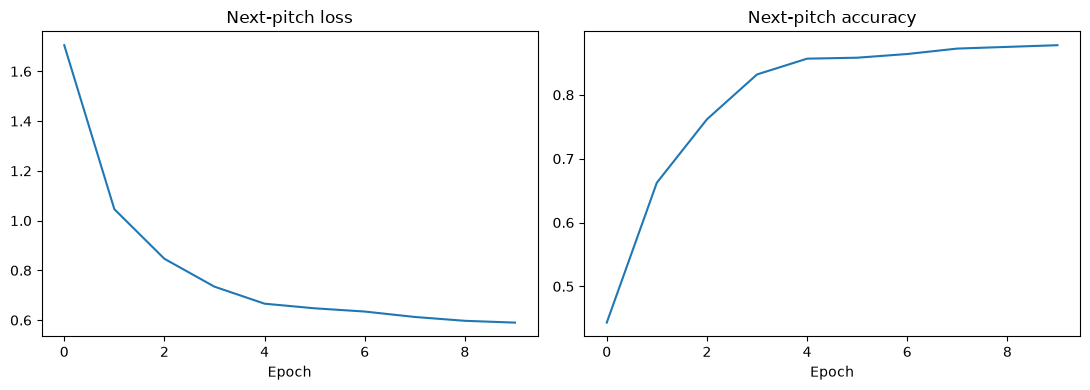

In [12]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(history_midi.history["loss"]); axs[0].set_title("Next-pitch loss"); axs[0].set_xlabel("Epoch")
axs[1].plot(history_midi.history["accuracy"]); axs[1].set_title("Next-pitch accuracy"); axs[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

### Generate and save a MIDI file
Same loop as for text: use the last 32 pitches as context, sample the next pitch, append, repeat 100 times. Then lay the generated notes on a timeline - a note every 0.3 s, each lasting 0.25 s - on a piano track, and write the `.mid` file.

In [13]:
seed = list(pitches[:SEQ_LEN])
generated_pitches = seed.copy()

for _ in range(100):
    context = np.array([generated_pitches[-SEQ_LEN:]])
    probabilities = model_midi.predict(context, verbose=0)[0]
    next_pitch = np.random.choice(128, p=probabilities / probabilities.sum())
    generated_pitches.append(int(next_pitch))

output = pretty_midi.PrettyMIDI()
piano = pretty_midi.Instrument(program=0)

for i, pitch in enumerate(generated_pitches[SEQ_LEN:]):
    start = i * 0.3
    end = start + 0.25
    piano.notes.append(pretty_midi.Note(velocity=90, pitch=int(pitch), start=start, end=end))

output.instruments.append(piano)
output.write("data/music/generated_midi.mid")
print("Generated MIDI saved successfully.")
print("Generated pitches:", generated_pitches[SEQ_LEN:SEQ_LEN + 20], "...")

Generated MIDI saved successfully.
Generated pitches: [59, 59, 56, 56, 56, 56, 59, 59, 59, 42, 42, 56, 56, 56, 57, 59, 59, 40, 56, 61] ...


### Inspect the result visually (piano roll)
Plot training vs generated notes: time on the x-axis, pitch on the y-axis.

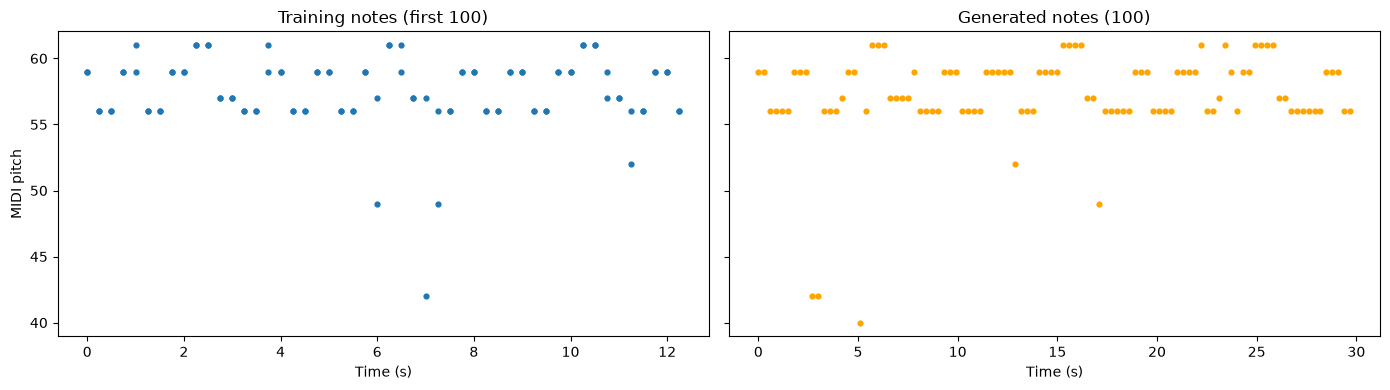

Generated file duration (s): 30.0 | notes: 100
Pitches used by generated music that were never in the training data: []


In [14]:
gen = pretty_midi.PrettyMIDI("data/music/generated_midi.mid")
gen_notes = gen.instruments[0].notes

fig, axs = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
orig = sorted(all_pitches)[:100]
axs[0].scatter([s for s, _ in orig], [p for _, p in orig], s=12); axs[0].set_title("Training notes (first 100)")
axs[1].scatter([n.start for n in gen_notes], [n.pitch for n in gen_notes], s=12, color="orange"); axs[1].set_title("Generated notes (100)")
for a in axs: a.set_xlabel("Time (s)")
axs[0].set_ylabel("MIDI pitch"); plt.tight_layout(); plt.show()

print("Generated file duration (s):", round(gen.get_end_time(), 1), "| notes:", len(gen_notes))
print("Pitches used by generated music that were never in the training data:",
      sorted(set(n.pitch for n in gen_notes) - set(pitches.tolist())))

## Summary
* **Char-RNN (ABC):** text -> integer ids -> many-to-many windows -> Embedding + LSTM + TimeDistributed softmax -> sample character by character. With a 70-character corpus the results are mostly noise until trained much longer (and then they memorise).
* **MIDI model:** notes -> pitch sequence -> next-pitch LSTM -> sampled pitches -> `.mid` file you can open in any MIDI player.
* To get genuinely good music: far more data (hundreds of tunes), longer training, and modelling note *durations/velocities* too, not just pitch.